In [1]:
import math
import matplotlib.pyplot as plt

import pandas as pd

import pyagrum as gum
import pyagrum.lib.notebook as gnb
import pyagrum.lib.dynamicBN as gdyn
import pyagrum.explain as explain
import pyagrum.lib.bn_vs_bn as bnvsbn

gum.about()
gnb.configuration()

pyAgrum 2.3.2
(c) 2015-2024 Pierre-Henri Wuillemin, Christophe Gonzales

    This is free software; see the source code for copying conditions.
    There is ABSOLUTELY NO WARRANTY; not even for MERCHANTABILITY or
    FITNESS FOR A PARTICULAR PURPOSE.  For details, see 'pyagrum.warranty'.
    


Library,Version
OS,posix [linux]
Python,"3.12.3 (main, Jun 19 2026, 12:46:00) [GCC 13.3.0]"
IPython,9.15.0
Matplotlib,3.11.0
Numpy,2.5.1
pyDot,4.0.1
pyAgrum,2.3.2


In [2]:
with open("elder_care_dbn/data/visits_added_waiting_times_hc_450_ed_50.csv", "r") as src:
  for _ in range(10):
    print(src.readline(), end="")

,Visit ID,Elder ID,Place of care,Place of origin,Diagnosis,Wait start,Start Time,End Time,Further care,waiting time,Waiting time over 30
0,0,37,Unit.HEALTH_CENTRE,Unit.INDEPENDENT,Sickness.NONE,0,0,1,Unit.INDEPENDENT,0,False
1,1,38,Unit.ED,Unit.INDEPENDENT,Sickness.DEAD,0,0,1,Unit.DEAD,0,False
2,2,42,Unit.HEALTH_CENTRE,Unit.INDEPENDENT,Sickness.MILD,0,0,1,Unit.FAMILY_CARE,0,False
3,3,46,Unit.ED,Unit.FAMILY_CARE,Sickness.MILD,0,0,1,Unit.INDEPENDENT,0,False
4,4,61,Unit.ED,Unit.FAMILY_CARE,Sickness.DIFFICULT,0,0,1,Unit.FAMILY_CARE,0,False
5,5,67,Unit.ED,Unit.HOME_CARE,Sickness.MILD,0,0,1,Unit.FAMILY_CARE,0,False
6,6,68,Unit.ED,Unit.HOME_CARE,Sickness.DIFFICULT,0,0,1,Unit.HOME_CARE_NEW_AIDS,0,False
7,7,87,Unit.ED,Unit.INDEPENDENT,Sickness.DIFFICULT,0,0,1,Unit.INDEPENDENT,0,False
8,8,100,Unit.ED,Unit.INDEPENDENT,Sickness.MEDIUM,0,0,1,Unit.INDEPENDENT,0,False


In [3]:
df = pd.read_csv("elder_care_dbn/data/visits_added_waiting_times_hc_450_ed_50.csv", index_col=0)
df.nunique()

Visit ID                67260
Elder ID                 4547
Place of care               2
Place of origin             4
Diagnosis                   5
Wait start                364
Start Time                364
End Time                  364
Further care                6
waiting time                9
Waiting time over 30        1
dtype: int64

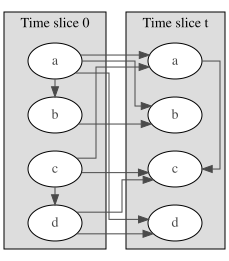

In [4]:
## hard coded BN
## twodbn=gum.BayesNet()
## a0,b0,c0,at,bt,ct=[twodbn.add(gum.LabelizedVariable(s,s,6))
#                   for s in ["a0","b0","c0","at","bt","ct"]]
## d0,dt=[twodbn.add(gum.LabelizedVariable(s,s,3))
#       for s in ["d0","dt"]]

## twodbn.addArc(a0,b0)

## twodbn.addArc(c0,d0)
## twodbn.addArc(c0,at)

## twodbn.addArc(a0,at)
## twodbn.addArc(a0,bt)
## twodbn.addArc(a0,dt)
## twodbn.addArc(b0,bt)
## twodbn.addArc(c0,ct)
## twodbn.addArc(d0,ct)
## twodbn.addArc(d0,dt)

## twodbn.addArc(at,ct)
## twodbn.generateCPTs()

## fast BN version

twodbn = gum.fastBN("d0[3]->ct<-at<-a0->b0->bt<-a0->dt[3]<-d0<-c0->ct;c0->at", 6)
#twodbn
gdyn.showTimeSlices(twodbn)

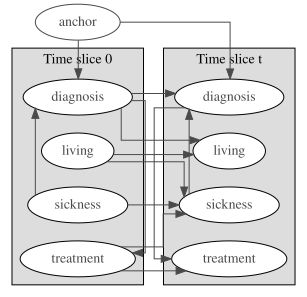

In [5]:
twodbn = gum.fastBN("diagnosis0[5]<-sickness0[5]->sicknesst[5]<-treatment0[3]<-diagnosis0[5]<-anchor;" \
"sicknesst[5]<-living0[6]->livingt[6]<-diagnosis0[5];diagnosis0[5]->diagnosist[5]<-anchor;" \
"treatment0[3]->treatmentt[3]<-diagnosist[5]<-sicknesst[5]")
#twodbn
gdyn.showTimeSlices(twodbn)

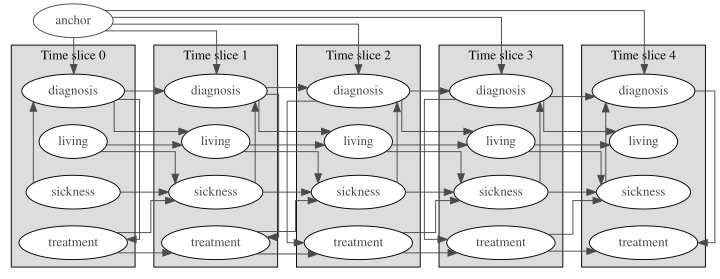

In [6]:
T = 5

dbn = gdyn.unroll2TBN(twodbn, T)
gdyn.showTimeSlices(dbn, size="10")


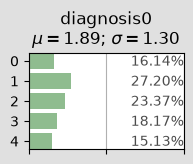
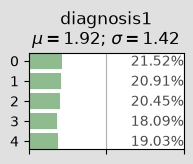
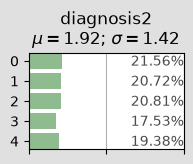
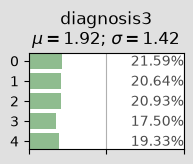
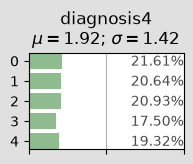

In [7]:
gnb.flow.clear()
for i in range(T):
  gnb.flow.add_html(gnb.getPosterior(dbn, target="diagnosis{}".format(i), evs={}), "$P(d{})$".format(i))
gnb.flow.display()

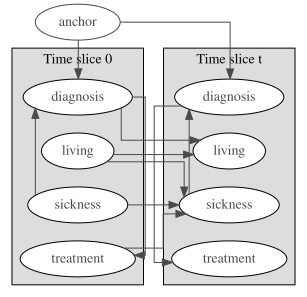

In [8]:
bn2 = gum.loadBN("elder_care_dbn/data/elder_twodbn.bif")
gdyn.showTimeSlices(bn2)


In [9]:

T = 1000
dbn2 = gdyn.unroll2TBN(bn2, T)
gum.saveBN(dbn2, "elder_care_dbn/data/dyn1000.pkl")
'''
dbn2 = gum.loadBN("elder_care_dbn/data/dyn1000.pkl")
'''

#gdyn.showTimeSlices(dbn2, size="10")


'\ndbn2 = gum.loadBN("elder_care_dbn/data/dyn1000.pkl")\n'


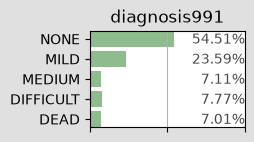
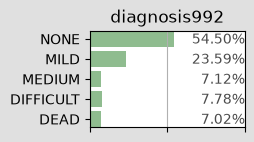
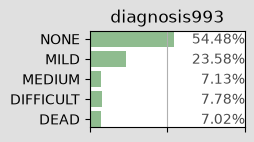
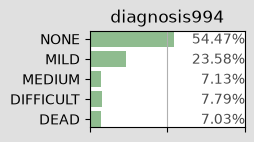
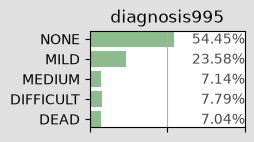
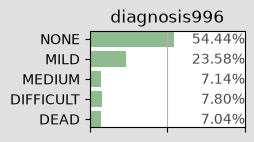
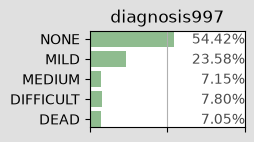
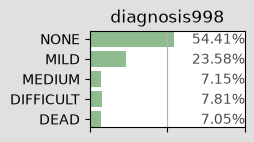
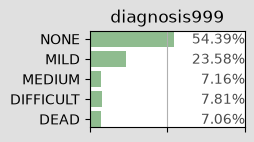

In [10]:


gnb.flow.clear()
for i in range(T-9,T,1):
  gnb.flow.add_html(gnb.getPosterior(dbn2, target="diagnosis{}".format(i), evs={}), "$P(d{})$".format(i))
gnb.flow.display()


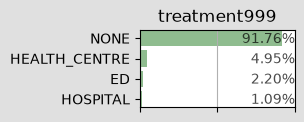
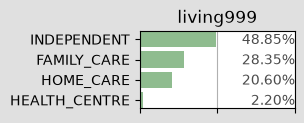

In [11]:
gnb.flow.add_html(gnb.getPosterior(dbn2, target="treatment{}".format(i), evs={}), "$P(d{})$".format(i))
gnb.flow.add_html(gnb.getPosterior(dbn2, target="living{}".format(i), evs={}), "$P(d{})$".format(i))
gnb.flow.display()

In [12]:
ie = gum.LazyPropagation(dbn2)

# an idea, albeit a bit dumb, would be so give preferences as evidence on the 
# outcome, and then it would (would it?) give the distribution that led to the evidence.
# does it even work that way lol?

ie.makeInference()
gnb.sideBySide(
    ie.posterior("diagnosis1"),
    ie.posterior("living1"))
gnb.sideBySide(
    ie.posterior("treatment1"),
    ie.posterior("sickness1"))
gnb.sideBySide(
    ie.posterior("anchor"))

ie.setEvidence({"treatment0":2})
ie.makeInference()
gnb.sideBySide(
    ie.posterior("diagnosis1"),
    ie.posterior("living1"))
gnb.sideBySide(
    ie.posterior("treatment1"),
    ie.posterior("sickness1"))
gnb.sideBySide(
    ie.posterior("anchor"))

ie.setEvidence({"treatment0":3})
ie.makeInference()
gnb.sideBySide(
    ie.posterior("diagnosis1"),
    ie.posterior("living1"))
gnb.sideBySide(
    ie.posterior("treatment1"),
    ie.posterior("sickness1"))
gnb.sideBySide(
    ie.posterior("anchor"))

ie.setEvidence({"treatment0":1})
ie.makeInference()
gnb.sideBySide(
    ie.posterior("diagnosis1"),
    ie.posterior("living1"))
gnb.sideBySide(
    ie.posterior("treatment1"),
    ie.posterior("sickness1"))
gnb.sideBySide(
    ie.posterior("anchor"))

In [14]:
from elder_care_dbn.cost_influence_diagram import expected_total_cost

T = 1000
total, per_timestep = expected_total_cost("elder_care_dbn/data/elder_twodbn.bif", T)
# print(f"expected daily cost per timestep: {per_timestep}")
print(f"expected total cost over {T} timesteps: {total}")

expected total cost over 1000 timesteps: 8521.370025896305
